# Notebook for selecting proteins for experimental validation

In [1]:
import pandas as pd 
import os
import itertools
peptide_name_abbreviations = {
    "MNEI_1IV7": "MN",
    "Thaumatin-I_1LR2": "TH",
    "Thaumatin-II_3AOK": "TH"
}
final_cols = ['original_id', 'protein_name', 'sequence', 'cysteine_count', 'disulfide_bridges']

# Load 0_de_novo_candidates.tsv, 0_foldseek_candidates.tsv and all_candidates.tsv
repo_path = os.path.dirname(os.getcwd())
repo_path = repo_path.split("WP2_Sweet_Protein_Discovery")[0] + "/WP2_Sweet_Protein_Discovery"
all_candidates = pd.read_csv(os.path.join(repo_path, "8_protein_selection", "1_merged_candidates.tsv"), sep = "\t")

import sys
sys.path.append(repo_path)
from utils import sequence_identity

# Using results from 0.5 sequence identity clustering using MMseqs2 
seq_id = "0.5"

# MNEI
# Read clustered sequences and get the highest similarity hit for each cluster.
# Removing cluster containing the de novo sequences (fixed_ and free_) to avoid biasing the selection towards de novo candidates.
mnei_clusters_df = pd.read_csv(f"{repo_path}/8_protein_selection/2_mmseqs_clustered_hits/MNEI_1IV7/MNEI_1IV7_{seq_id}_cluster.tsv", sep="\t", header=None, names=["cluster_id", "target_id"])
mnei_clusters_df = mnei_clusters_df.drop_duplicates()
mnei_clusters_df = mnei_clusters_df.merge(all_candidates, on = "target_id", how = "inner")
mnei_clusters_df = mnei_clusters_df.sort_values(by=['cluster_id', 'avg_sweet_res_similarity'], ascending=[True, False])
mnei_clusters_df['representative_hit'] = mnei_clusters_df.groupby('cluster_id')['target_id'].transform('first')
mnei_clusters_df = mnei_clusters_df[~mnei_clusters_df["representative_hit"].str.startswith(("fixed", "free"))]
mnei_clusters_df = mnei_clusters_df.drop(columns=['cluster_id'])
print("MNEI has " + str(mnei_clusters_df["representative_hit"].nunique()) + " unique representative hits.")

# Selecting the top 10 clusters based on avg_sweet_res_similarity and keeping only the representative hit for each cluster
# based on the similarity of sweet residues
mnei_selected_df = mnei_clusters_df.sort_values(by='avg_sweet_res_similarity', ascending=False).groupby('representative_hit').head(1).head(10)
mnei_selected_df["rank"] = mnei_selected_df["avg_sweet_res_similarity"].rank(ascending=False)

# Thaumatin-I and Thaumatin-II
# First, get the top 5 most similar sequences based on of3_tm_align_seq_id, regardless of cluster.
# These are likely to have similar folds to the query and we want to keep them in the selection to ensure we have some candidates with similar folds to the query.
# Then, for the rest of the hits, we will drop all other hits in the same cluster and keep only the representative hit (the one with the highest similarity to the query) to ensure we have a diverse set of candidates.
similar_folds = all_candidates[all_candidates["query"] != "MNEI_1IV7"].sort_values(by=['of3_tm_align_seq_id'], ascending=[False]).head(5)["target_id"].to_list()
thaumatin_clusters_df = pd.read_csv(f"{repo_path}/8_protein_selection/2_mmseqs_clustered_hits/Thaumatin/Thaumatin_{seq_id}_cluster.tsv", sep="\t", header=None, names=["cluster_id", "target_id"])
clusters_to_drop = []
for fold in similar_folds:
    cluster_id = thaumatin_clusters_df[thaumatin_clusters_df["target_id"] == fold]["cluster_id"].values[0]
    clusters_to_drop.append(cluster_id)

# Remove clusters containing the similar folds and keep only the representative hit for each cluster to ensure we have a diverse set of candidates.
thaumatin_clusters_df = thaumatin_clusters_df[~thaumatin_clusters_df["cluster_id"].isin(clusters_to_drop)]
thaumatin_clusters_df = thaumatin_clusters_df.drop_duplicates()
thaumatin_clusters_df = thaumatin_clusters_df.merge(all_candidates, on = "target_id", how = "inner")

# Sort by cluster_id and avg_sweet_res_similarity to get the most similar hit for each cluster at the top, then keep only the representative hit for each cluster.
thaumatin_clusters_df = thaumatin_clusters_df.sort_values(by=['cluster_id', 'avg_sweet_res_similarity'], ascending=[True, False])
thaumatin_clusters_df['representative_hit'] = thaumatin_clusters_df.groupby('cluster_id')['target_id'].transform('first')
thaumatin_clusters_df = thaumatin_clusters_df.drop(columns=['cluster_id'])
print("Thaumatin has " + str(thaumatin_clusters_df["representative_hit"].nunique()) + " unique representative hits.")

# For Thaumatin, take the top 10 clusters based on avg_sweet_res_similarity and keep only the representative hit for each cluster
thaumatin_selected_df = thaumatin_clusters_df.sort_values(by='avg_sweet_res_similarity', ascending=False).groupby('representative_hit').head(1).head(5)
thaumatin_similar_df = all_candidates[all_candidates["target_id"].isin(similar_folds)]
thaumatin_final_df = pd.concat([thaumatin_selected_df, thaumatin_similar_df]).drop_duplicates(subset=["target_id"])
thaumatin_final_df = thaumatin_final_df.sort_values(by='avg_sweet_res_similarity', ascending=False)
thaumatin_final_df["rank"] = thaumatin_final_df["avg_sweet_res_similarity"].rank(ascending=False)

# Concatenate the selected candidates for MNEI and Thaumatin and save to a new dataframe
final_representatives = pd.concat([mnei_selected_df, thaumatin_final_df])
final_representatives["rank"] = final_representatives["rank"].astype(int)
final_representatives["protein_name"] = final_representatives.apply(lambda row: peptide_name_abbreviations[row["query"]] + "_" + str(int(row["rank"])), axis = 1)
final_representatives = final_representatives.rename(columns={"target_id": "original_id"})
final_representatives = final_representatives[final_cols].copy()
final_representatives

MNEI has 33 unique representative hits.
Thaumatin has 21 unique representative hits.


,original_id,protein_name,sequence,cysteine_count,disulfide_bridges
110,OneKP_scaffold-AALA-2005416-Meliosma_cuneifolia,MN_1,GGWTKIEDVKKNEEIQDLGRFSVEKFNKNKEQYQAKGRNKHDLTFS...,0.0,[]
0,A0A8B8NA16,MN_2,GEWNPIKDVRNPHVKEIGEFAVTEFNKDPQHGADLQFQSVIKGETQ...,0.0,[]
148,A0A7N1A7N7,MN_3,GGWQPIKNLDDKEIRELAKFALTEHRKLGGPRLEFERVLEGEQQVV...,0.0,[]
1,OneKP_scaffold-KWGC-2062037-Crassula_perforata,MN_4,GGLMEIEDVEHNKEVQDLGKFSVAQYNNKLAEKNKLLEFVQVVSAE...,0.0,[]
2,A0A7N0UIJ2,MN_5,GGWKKISNLTDPSIIAIAEFAVEEAAKVNTHTSSLTFKRIRSGKYQ...,0.0,[]
3,A0A9Q0G024,MN_6,GGWEPVSNHDPHVREVGEFAVRAYNEQGKIKGAGLKFESVLKAARQ...,0.0,[]
159,A0A0D3FFA6,MN_7,GSWEPVDINDPHVQELGRWAVAEEDRGVAAGGLTFERVTDGEKQVV...,0.0,[]
4,A0ABP0U637,MN_8,GAPKNIPNSNSVEIRELANFAVSQYNSGKNVVHKLSFSKVVSAREQ...,1.0,[]
169,A0AB40C3D9,MN_9,GGRTEIKNVKSNKMVQSLGKFAVEEYDKGVKGGSNAAALVSFSSVI...,0.0,[]
70,OneKP_scaffold-YKFU-2009113-Peltoboykinia_wata...,MN_10,GGRTKIRDVKSNQEVQNLGKFSVEEYNKQSRQNGGLLMFKEVVEAE...,0.0,[]


# De novo designed sequences for MNEI

In [2]:
# Sort based on avg_sweet_res_similarity and remove sequences with high sequence identity
de_novo_candidates = pd.read_csv(os.path.join(repo_path, "8_protein_selection", "0_de_novo_candidates.tsv"), sep = "\t")
de_novo_candidates = de_novo_candidates.sort_values(by="avg_sweet_res_similarity", ascending=False)
de_novo_candidates["disulfide_bridges"] = None

seq_ids = []
for (index1, row1), (index2, row2) in itertools.combinations(de_novo_candidates.iterrows(), 2):
    candidate_seq = row1["sequence"]
    representative_seq = row2["sequence"]
    identity = sequence_identity(candidate_seq, representative_seq)
    seq_ids.append([row1["id"], row2["id"], identity])

# Removing sequences with high sequence identity (>= 95%) to other candidates to ensure we have a diverse set of candidates.
seq_ids_df = pd.DataFrame(seq_ids, columns=["id", "id_2", "identity"])
seq_ids_df = seq_ids_df[seq_ids_df["identity"] >= 0.95].copy()
ids_to_drop = seq_ids_df["id_2"].unique()
de_novo_candidates = de_novo_candidates[~de_novo_candidates["id"].isin(ids_to_drop)] 

# Choose top 5 candidates from fixed and free each based on avg_sweet_res_similarity, ensuring that there are no duplicate sequences in the final selection.
fixed_candidates = de_novo_candidates[de_novo_candidates["id"].str.startswith("fixed_")].copy()
fixed_candidates = fixed_candidates.sort_values(by="avg_sweet_res_similarity", ascending=False).head(5)["id"].to_list()
free_candidates = de_novo_candidates[de_novo_candidates["id"].str.startswith("free_")].copy()
free_candidates = free_candidates.sort_values(by="avg_sweet_res_similarity", ascending=False).head(5)["id"].to_list()

# Merge the two de novo lists and show the selected de novo candidates.
free_candidates_df = de_novo_candidates[de_novo_candidates["id"].isin(free_candidates)].copy()
fixed_candidates_df = de_novo_candidates[de_novo_candidates["id"].isin(fixed_candidates)].copy()
final_de_novo_candidates_df = pd.concat([free_candidates_df, fixed_candidates_df])
final_de_novo_candidates_df = final_de_novo_candidates_df.sort_values(by="avg_sweet_res_similarity", ascending=False)
final_de_novo_candidates_df["rank"] = final_de_novo_candidates_df["avg_sweet_res_similarity"].rank(ascending=False)
final_de_novo_candidates_df["rank"] = final_de_novo_candidates_df["rank"].astype(int)
final_de_novo_candidates_df["original_id"] = final_de_novo_candidates_df["id"]

final_de_novo_candidates_df["protein_name"] = None
for index, row in final_de_novo_candidates_df.iterrows():
    protein_name = f"MN_de_novo_{str(row['rank'])}"
    final_de_novo_candidates_df.at[index, "disulfide_bridges"] = []
    final_de_novo_candidates_df.at[index, "protein_name"] = protein_name

final_de_novo_candidates_df = final_de_novo_candidates_df[final_cols].copy()
final_de_novo_candidates_df

,original_id,protein_name,sequence,cysteine_count,disulfide_bridges
0,fixed_02_MNEI_1IV7_8,MN_de_novo_1,MEEEIIPVDEFTQELGKFAVEEENKRGQFGKLTFDKVLEPCIKKTI...,1,[]
3,fixed_015_MNEI_1IV7_3,MN_de_novo_2,SEERVVPVDDFTQELGKFAVEEENKRGQFGKLTFDKVLAPCIKHTI...,1,[]
5,fixed_015_MNEI_1IV7_15,MN_de_novo_3,MEKEVIPIDEFTQELGKFAVEEENKKGQFGKLTFDKVLEPCIKYTI...,1,[]
6,fixed_02_MNEI_1IV7_18,MN_de_novo_4,METEIIPIGPFTEELGRFAVEEENKRGQFGKLTFDKVLEPCIKHTI...,1,[]
7,fixed_025_MNEI_1IV7_15,MN_de_novo_5,MEKEVLPIDEFTQELGKFAVEEENKKGQFGKLTFDKVLEPCIKETI...,1,[]
33,free_03_MNEI_1IV7_18,MN_de_novo_6,MEEEIIPVDEFTQELGKFAVEEQNKEGKFGELTFDKVVEPVIKKTI...,0,[]
34,free_025_MNEI_1IV7_19,MN_de_novo_7,MKREVVPVGPETQELGKFAVEEVNKDGKFGTLTFDEVLPPVIKETI...,0,[]
36,free_01_MNEI_1IV7_15,MN_de_novo_8,MEEEIVPVDEFTQELGKFAVEEQNKKGEFGKLTFDKVVEPVIKHTI...,0,[]
37,free_025_MNEI_1IV7_7,MN_de_novo_9,MEKEIVPVNEETQELGKFAVEQENKNGKFGKLTFDKVIEPVTKTTL...,0,[]
38,free_025_MNEI_1IV7_14,MN_de_novo_10,AEKEIVPVGPFTQELGKFAVEEENKRGKFGKLEFDKVVEPVVKETL...,0,[]


In [3]:
quote_proteins = pd.concat([final_representatives, final_de_novo_candidates_df]).reset_index(drop=True)

# Read original sequences
foldseek_uniprot_df = pd.read_csv(f"{repo_path}/3_foldseek_search/foldseek_UniProt_search.tsv", sep = "\t")
foldseek_onekp_df = pd.read_csv(f"{repo_path}/3_foldseek_search/foldseek_OneKP_search.tsv", sep = "\t")
# Keep only target and tseq
foldseek_uniprot_df = foldseek_uniprot_df[["target", "tseq"]].copy()
foldseek_onekp_df = foldseek_onekp_df[["target", "tseq"]].copy()
# Merge the two foldseek results to get the original sequences for all candidates
foldseek_df = pd.concat([foldseek_uniprot_df, foldseek_onekp_df]).drop_duplicates(subset=["target"]).copy()
quote_proteins = quote_proteins.merge(foldseek_df, left_on="original_id", right_on="target", how="left").drop(columns=["target"]).rename(columns={"tseq": "full_sequence"})

# Peptide name = peptide_name_abbreviation + rank 
rename_cols = {
    "protein_name": "Protein_ID",
    "cysteine_count": "Cysteine_Count",
    "sequence": "Sequence",
    "disulfide_bridges": "Disulfide_Bridges",
    "original_id": "Original_ID",
    "full_sequence": "Full Sequence"
}

quote_proteins = quote_proteins.rename(columns = rename_cols)
quote_proteins = quote_proteins[rename_cols.values()]

# Save fasta file of the selected candidates for synthesis
fasta_path = os.path.join(repo_path, "8_protein_selection", "3_genscript_quote.fasta")
if os.path.exists(fasta_path):
    os.remove(fasta_path)
for index, row in quote_proteins.iterrows():
    fasta_header = f">{row['Protein_ID']}"
    if pd.isna(row["Full Sequence"]):
        fasta_sequence = row["Sequence"]
    else:
        fasta_sequence = row["Full Sequence"]
    fasta_entry = f"{fasta_header}\n{fasta_sequence}\n"
    with open(fasta_path, "a") as fasta_file:
        fasta_file.write(fasta_entry)

# Add DeepLoc 2 predictions to the resulting dataframe
DeepLoc 2 was run using the following command:
```
deeploc2 -f 3_genscript_quote.fasta -m Fast -o ./3_deeploc2_results
```

In [4]:
deeploc_res = f"{repo_path}/8_protein_selection/3_deeploc2_results/results_20260511-204425.csv"
deeploc_df = pd.read_csv(deeploc_res)
deeploc_df = deeploc_df[deeploc_df["Protein_ID"].isin(quote_proteins["Protein_ID"])]
deeploc_df = deeploc_df[["Protein_ID", "Localizations", "Membrane types", "Signals"]]
deeploc_df = deeploc_df.rename(columns={
    "Membrane types": "Membrane_Types"
})

# Merge to quote_proteins to get the localization information for each candidate
quote_proteins_final = quote_proteins.merge(deeploc_df, on="Protein_ID", how="inner")
quote_proteins_final[["Protein_ID", "Original_ID", "Sequence"]].to_csv(os.path.join(repo_path, "8_protein_selection", "3_genscript_quote_id_mapping.csv"), index = False)
quote_proteins_final_df = quote_proteins_final.drop(columns=["Original_ID"])
quote_proteins_final_df.to_csv(os.path.join(repo_path, "8_protein_selection", "3_genscript_quote.csv"), index = False)
quote_proteins_final_df

,Protein_ID,Cysteine_Count,Sequence,Disulfide_Bridges,Full Sequence,Localizations,Membrane_Types,Signals
0,MN_1,0.0,GGWTKIEDVKKNEEIQDLGRFSVEKFNKNKEQYQAKGRNKHDLTFS...,[],FRYSALIFFLLVCISSISVDGFGRKVGGWTKIEDVKKNEEIQDLGR...,Nucleus,Soluble,Nuclear localization signal
1,MN_2,0.0,GEWNPIKDVRNPHVKEIGEFAVTEFNKDPQHGADLQFQSVIKGETQ...,[],NaN,Extracellular,Soluble,NaN
2,MN_3,0.0,GGWQPIKNLDDKEIRELAKFALTEHRKLGGPRLEFERVLEGEQQVV...,[],NaN,Extracellular,Soluble,Nuclear localization signal
3,MN_4,0.0,GGLMEIEDVEHNKEVQDLGKFSVAQYNNKLAEKNKLLEFVQVVSAE...,[],GGKLGGLMEIEDVEHNKEVQDLGKFSVAQYNNKLAEKNKLLEFVQV...,Nucleus,Soluble,Nuclear localization signal
4,MN_5,0.0,GGWKKISNLTDPSIIAIAEFAVEEAAKVNTHTSSLTFKRIRSGKYQ...,[],NaN,Extracellular,Soluble,NaN
5,MN_6,0.0,GGWEPVSNHDPHVREVGEFAVRAYNEQGKIKGAGLKFESVLKAARQ...,[],NaN,Extracellular,Soluble,NaN
6,MN_7,0.0,GSWEPVDINDPHVQELGRWAVAEEDRGVAAGGLTFERVTDGEKQVV...,[],NaN,Extracellular,Soluble,NaN
7,MN_8,1.0,GAPKNIPNSNSVEIRELANFAVSQYNSGKNVVHKLSFSKVVSAREQ...,[],NaN,Nucleus|Extracellular,Soluble,NaN
8,MN_9,0.0,GGRTEIKNVKSNKMVQSLGKFAVEEYDKGVKGGSNAAALVSFSSVI...,[],NaN,Nucleus,Soluble,Nuclear localization signal
9,MN_10,0.0,GGRTKIRDVKSNQEVQNLGKFSVEEYNKQSRQNGGLLMFKEVVEAE...,[],GRFVGGRTKIRDVKSNQEVQNLGKFSVEEYNKQSRQNGGLLMFKEV...,Nucleus,Soluble,Nuclear localization signal


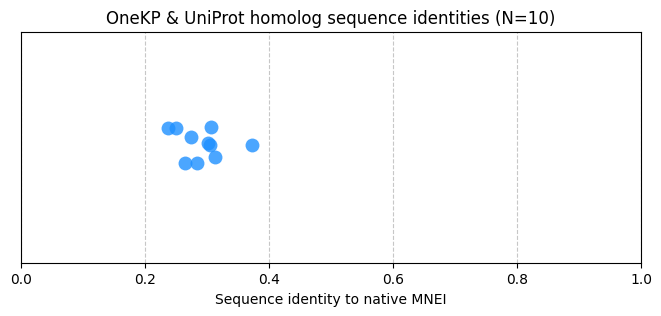

In [ ]:
tm_score_df = "/Users/pqh443/Documents/Git_projects/WP2_Sweet_Protein_Discovery/6_structural_analyses/4_openfold3_predictions/monomer_tm_scores.csv"
tm_score_df = pd.read_csv(tm_score_df)
# If target contains | then split it and take the second part as the target id
tm_score_df["target"] = tm_score_df["target"].apply(lambda x: x.split("|")[1] if "|" in x else x)
tm_score_df = tm_score_df[tm_score_df["target"].isin(quote_proteins_final["Original_ID"])]

import matplotlib.pyplot as plt
import seaborn as sns

mnei_hits = tm_score_df[tm_score_df["query"] == "MNEI_1IV7"].copy()
thaumatin_hits = tm_score_df[tm_score_df["query"].str.startswith("Thaumatin")].copy()

plt.figure(figsize=(8, 3)) # Wider, shorter figure looks better for 1D plots

# Create a strip plot. jitter=True slightly offsets points that have the exact same value so they don't hide each other.
sns.stripplot(x=mnei_hits["of3_tm_align_seq_id"], size=10, alpha=0.8, jitter=True, color='dodgerblue')

plt.xlabel('Sequence identity to native MNEI')
plt.title("OneKP & UniProt homolog sequence identities (N=10)")
plt.xlim(0.0, 1.0)
plt.tick_params(axis='y', left=False) # Remove y-axis ticks since they don't represent meaningful values
plt.ylim(-0.5, 0.5) # Remove y-axis since it's not meaningful for a strip plot
plt.grid(axis='x', linestyle='--', alpha=0.7) # Helpful visual guide
plt.show()

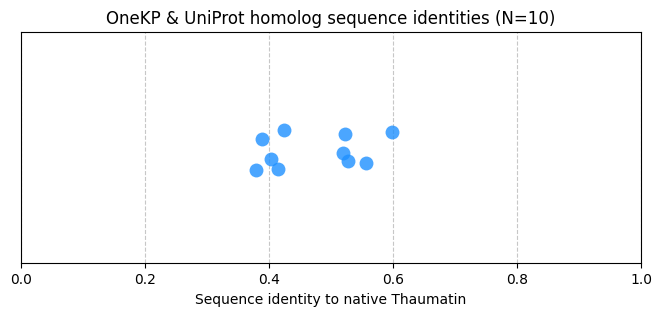

In [23]:
plt.figure(figsize=(8, 3)) # Wider, shorter figure looks better for 1D plots

# Create a strip plot. jitter=True slightly offsets points that have the exact same value so they don't hide each other.
sns.stripplot(x=thaumatin_hits["of3_tm_align_seq_id"], size=10, alpha=0.8, jitter=True, color='dodgerblue')

plt.xlabel('Sequence identity to native Thaumatin')
plt.title("OneKP & UniProt homolog sequence identities (N=10)")
plt.xlim(0.0, 1.0)
plt.tick_params(axis='y', left=False) # Remove y-axis ticks since they don't represent meaningful values
plt.ylim(-0.5, 0.5) # Remove y-axis since it's not meaningful for a strip plot
plt.grid(axis='x', linestyle='--', alpha=0.7) # Helpful visual guide
plt.show()

In [9]:
tm_score_df

,query,target,of3_tm_score,of3_RMSD,of3_tm_align_start,of3_tm_align_end,of3_avg_pLDDT,of3_tm_align_seq_id,of3_tm_align_length,model,source,length_diff,interface_residues,grantham_score,pdb,cropped_tseq,best_model
1811,MNEI_1IV7,OneKP_scaffold-YKFU-2009113-Peltoboykinia_wata...,0.78978,1.29,0.0,91.0,88.681957,0.313,83,OF3,OneKP,0.041667,"[('E', 22, 'Y'), ('Q', 27, 'N'), ('C', 40, 'A'...",109.142857,MNEI_1IV7___OneKP_scaffold-YKFU-2009113-Peltob...,GGRTKIRDVKSNQEVQNLGKFSVEEYNKQSRQNGGLLMFKEVVEAE...,MNEI_1IV7___OneKP_scaffold-YKFU-2009113-Peltob...
1823,MNEI_1IV7,OneKP_scaffold-AALA-2005416-Meliosma_cuneifolia,0.78102,1.28,0.0,96.0,85.374845,0.305,82,AF3,OneKP,0.010417,"[('E', 22, 'F'), ('Q', 27, 'Q'), ('C', 40, 'A'...",113.714286,MNEI_1IV7___OneKP_scaffold-AALA-2005416-Melios...,GGWTKIEDVKKNEEIQDLGRFSVEKFNKNKEQYQAKGRNKHDLTFS...,MNEI_1IV7___OneKP_scaffold-AALA-2005416-Melios...
1873,MNEI_1IV7,OneKP_scaffold-KWGC-2062037-Crassula_perforata,0.77786,1.79,0.0,94.0,88.976316,0.250,84,OF3,OneKP,0.010417,"[('E', 22, 'Y'), ('Q', 27, 'A'), ('C', 40, 'A'...",121.428571,MNEI_1IV7___OneKP_scaffold-KWGC-2062037-Crassu...,GGLMEIEDVEHNKEVQDLGKFSVAQYNNKLAEKNKLLEFVQVVSAE...,MNEI_1IV7___OneKP_scaffold-KWGC-2062037-Crassu...
3285,Thaumatin-I_1LR2,OneKP_scaffold-OSMU-2076676-Lycium_sp.,0.95389,1.08,0.0,207.0,94.448942,0.598,204,OF3,OneKP,0.004831,"[('K', 66, 'E'), ('K', 77, 'Q'), ('K', 96, 'L'...",73.625000,Thaumatin-I_1LR2___OneKP_scaffold-OSMU-2076676...,ATFNIINRCTYTVWAAASSGEGKQLNSGRQLNSGQSWTLNVNPGTV...,Thaumatin-I_1LR2___OneKP_scaffold-OSMU-2076676...
3322,Thaumatin-II_3AOK,OneKP_scaffold-QDVW-2000188-Saruma_henryi,0.93734,1.29,0.0,207.0,88.726442,0.520,202,AF3,OneKP,0.004831,"[('R', 66, 'R'), ('K', 77, 'E'), ('R', 81, 'T'...",70.000000,Thaumatin-II_3AOK___OneKP_scaffold-QDVW-200018...,TTFHITNRCPFTIWAAAIDYSRGLAAAAESGRRLNSGQSWTLEVGR...,Thaumatin-II_3AOK___OneKP_scaffold-QDVW-200018...
3570,Thaumatin-II_3AOK,OneKP_scaffold-ORKS-2009548-Philonotis_fontana,0.93882,1.44,0.0,220.0,97.779638,0.415,205,OF3,OneKP,0.067633,"[('R', 66, 'Q'), ('K', 77, 'G'), ('R', 81, 'N'...",84.333333,Thaumatin-II_3AOK___OneKP_scaffold-ORKS-200954...,ATFNFVNSCKFTVWVGLQPNGGLPLLAEGGFQMLAGAQHGVTAPAT...,Thaumatin-II_3AOK___OneKP_scaffold-ORKS-200954...
3630,Thaumatin-I_1LR2,OneKP_scaffold-ZJRC-2024142-ZJRC-Sambucus_cana...,0.90736,1.83,0.0,221.0,95.451802,0.379,203,AF3,OneKP,0.072464,"[('K', 66, 'A'), ('K', 77, 'G'), ('K', 96, 'Q'...",63.000000,Thaumatin-I_1LR2___OneKP_scaffold-ZJRC-2024142...,LILTVVNNCPFTIWPAIQPNSGHAVLERGGFALNSLTHRSFPAPTQ...,Thaumatin-I_1LR2___OneKP_scaffold-ZJRC-2024142...


In [196]:
de_novo_path = f"{repo_path}/7_de_novo_designs/3_selected_designs"
of3_path = f"{repo_path}/6_structural_analyses/4_openfold3_predictions/surfdiff_structures"
structure_dir = f"{repo_path}/8_protein_selection/4_candidate_structures/"
os.makedirs(structure_dir, exist_ok=True)
for index, row in quote_proteins_final.iterrows():
    # If the candidate is a de novo design, copy the structure from the de novo designs folder, otherwise copy the structure from the of3 predictions folder.
    if row["Original_ID"].startswith("fixed_") or row["Original_ID"].startswith("free_"):
        structure_path = os.path.join(de_novo_path, f"{row['Original_ID']}.pdb")
        structure_sub_dir = os.path.join(structure_dir, "MNEI_1IV7")
    elif row["Protein_ID"].startswith("MN_"):
        structure_path = os.path.join(of3_path, "MNEI_1IV7/pdb_dir", f"{row['Original_ID']}.pdb")
        structure_sub_dir = os.path.join(structure_dir, "MNEI_1IV7")
    else:
        if os.path.exists(os.path.join(of3_path, "Thaumatin-I_1LR2/pdb_dir", f"{row['Original_ID']}.pdb")):
            structure_path = os.path.join(of3_path, "Thaumatin-I_1LR2/pdb_dir", f"{row['Original_ID']}.pdb")
            structure_sub_dir = os.path.join(structure_dir, "Thaumatin-I_1LR2")
        else:
            structure_path = os.path.join(of3_path, "Thaumatin-II_3AOK/pdb_dir", f"{row['Original_ID']}.pdb")
            structure_sub_dir = os.path.join(structure_dir, "Thaumatin-II_3AOK")
    os.makedirs(structure_sub_dir, exist_ok=True)

    if os.path.exists(structure_path):
        print(f"Copying structure for {row['Protein_ID']} from {structure_path} to {structure_dir}")
        os.system(f"cp {structure_path} {structure_sub_dir}/")
    else:
        print(f"Structure for {row['Protein_ID']} not found at {structure_path}. Skipping copy.")

Copying structure for MN_1 from /Users/pqh443/Documents/Git_projects//WP2_Sweet_Protein_Discovery/6_structural_analyses/4_openfold3_predictions/surfdiff_structures/MNEI_1IV7/pdb_dir/OneKP_scaffold-AALA-2005416-Meliosma_cuneifolia.pdb to /Users/pqh443/Documents/Git_projects//WP2_Sweet_Protein_Discovery/8_protein_selection/4_candidate_structures/
Copying structure for MN_2 from /Users/pqh443/Documents/Git_projects//WP2_Sweet_Protein_Discovery/6_structural_analyses/4_openfold3_predictions/surfdiff_structures/MNEI_1IV7/pdb_dir/A0A8B8NA16.pdb to /Users/pqh443/Documents/Git_projects//WP2_Sweet_Protein_Discovery/8_protein_selection/4_candidate_structures/
Copying structure for MN_3 from /Users/pqh443/Documents/Git_projects//WP2_Sweet_Protein_Discovery/6_structural_analyses/4_openfold3_predictions/surfdiff_structures/MNEI_1IV7/pdb_dir/A0A7N1A7N7.pdb to /Users/pqh443/Documents/Git_projects//WP2_Sweet_Protein_Discovery/8_protein_selection/4_candidate_structures/
Copying structure for MN_4 from /